# Can you find momentum? An entry for The Side Quest

**Answer first.** In 241,775 NFL plays from 2019 to 2025, tested only after the rules were committed (`PREREG.md`), a successful play is followed by a successful play 4.3 percentage points more often than a failed one. The situation it leaves you in explains 3.9 points, who was better that half explains 0.45, and what is left for momentum is **−0.02 (95% range −0.41 to +0.37)**. Drive-to-drive, offense-to-defense, fumble-bounce, big-moment, crowd and empty-stadium tests also come back empty after correction. Planted momentum of 0.5 points is caught 80% of the time, so this is a measured zero, not a blind spot.

The only place something shows up is college: drives stay slightly streaky within a half and reset at halftime, worth about 0.03 points per drive.

This notebook reads the saved results and draws the figures. The full pipeline is `run_all.sh`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RES, FIG = ROOT / "results", ROOT / "figures"
R = {k: json.loads((RES / f"{k}.json").read_text()) for k in ["discovery_nfl", "holdout_nfl", "fresh_nfl", "discovery_cfb", "holdout_cfb"]}
E = json.loads((RES / "exploratory_nfl.json").read_text())
NAVY, OR, ICE, SLATE = "#0a2343", "#fb4f14", "#7cc4ff", "#5a7396"
plt.rcParams.update({"figure.facecolor": NAVY, "axes.facecolor": NAVY, "axes.edgecolor": "#33507a", "axes.labelcolor": "#dfe7f2",
                     "xtick.color": "#a3b4cc", "ytick.color": "#a3b4cc", "text.color": "#f3f6fb", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 1. The four pre-registered tests, every sample

Excess = estimate minus the shuffle baseline. P4 is the covariate-adjusted fumble effect. Holm correction across the four tests within each sample.

In [2]:
rows = []
for k, r in R.items():
    for t in ["P1", "P2", "P3", "P4"]:
        x = r[t]
        est = x.get("excess", x.get("est")); sd = x.get("null_sd", x.get("se"))
        rows.append(dict(sample=k, test=t, estimate=est * (100 if t == "P1" else 1), se=sd * (100 if t == "P1" else 1),
                         p=x.get("p", x.get("p_ri")), holm=r["holm"][t], n=x.get("n_pairs", x.get("n"))))
tab = pd.DataFrame(rows)
tab.pivot(index="test", columns="sample", values="estimate").round(3)

sample,discovery_cfb,discovery_nfl,fresh_nfl,holdout_cfb,holdout_nfl
test,,,,,
P1,-0.904,-0.043,-0.204,-0.596,-0.024
P2,0.005,0.002,-0.007,0.007,0.006
P3,-0.010,0.001,0.037,-0.016,0.008
P4,0.035,-0.041,-0.188,-0.119,0.366


In [3]:
tab.pivot(index="test", columns="sample", values="holm").round(3)

sample,discovery_cfb,discovery_nfl,fresh_nfl,holdout_cfb,holdout_nfl
test,,,,,
P1,0.002,1.0,1.000,0.002,0.903
P2,0.227,1.0,1.000,0.236,0.654
P3,0.046,1.0,0.518,0.022,0.654
P4,0.711,1.0,1.000,0.410,0.176


## 2. Where the 4.3 points go (NFL 2019–2025)

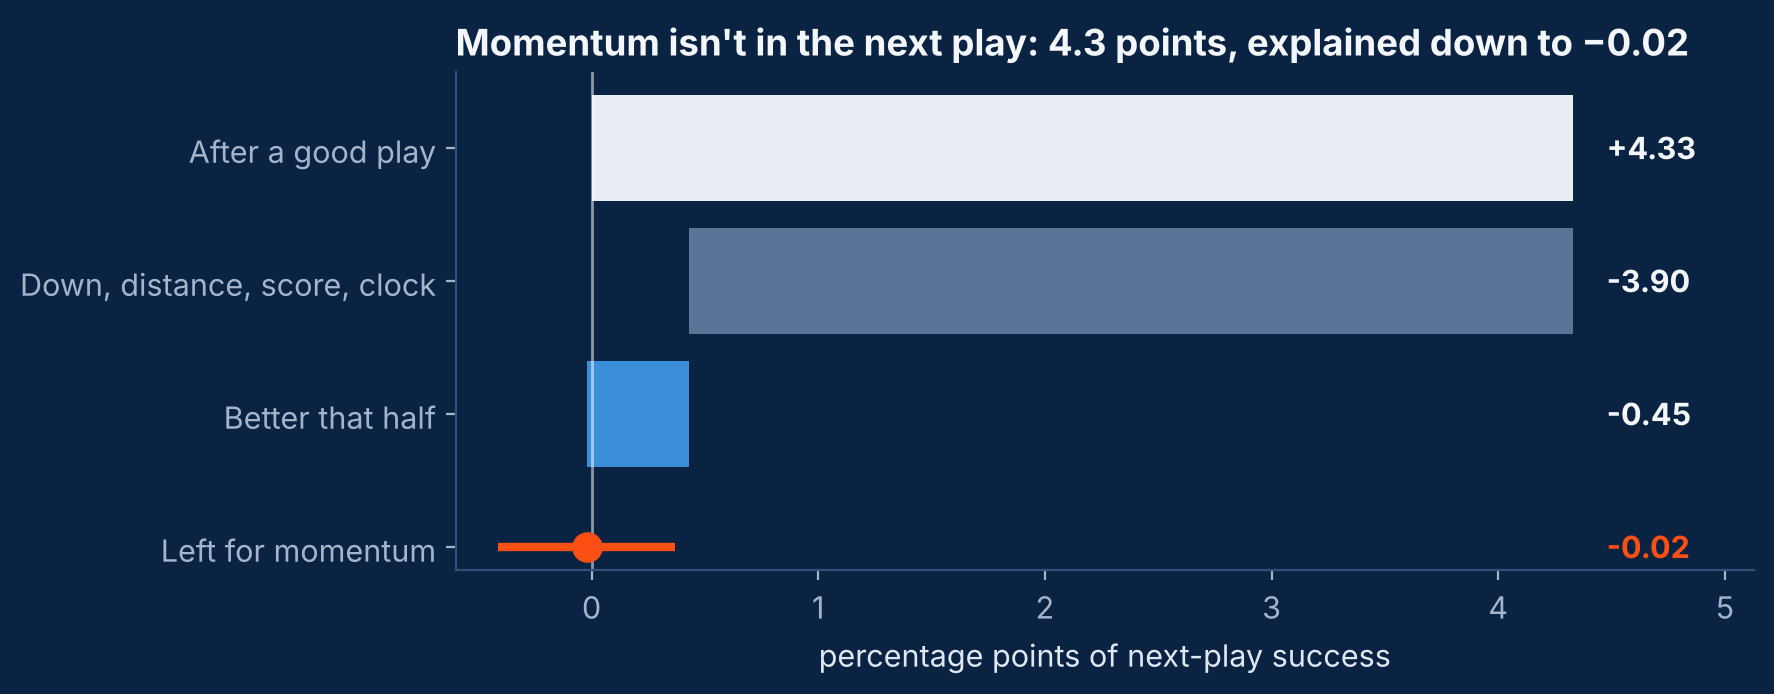

In [4]:
w = R["holdout_nfl"]["waterfall"]
raw, after = w["raw"]*100, w["after_situation"]*100; team, order = w["team_half_level"]*100, w["order"]*100; sd = w["order_sd"]*100
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ["After a good play", "Down, distance, score, clock", "Better that half", "Left for momentum"]
ax.barh(3, raw, color="#e9eef6"); ax.barh(2, raw - after, left=after, color=SLATE); ax.barh(1, after - order, left=order, color="#3b8fd9")
ax.errorbar(order, 0, xerr=1.96*sd, fmt="o", color=OR, ms=10, capsize=0, lw=3)
ax.set_yticks([3, 2, 1, 0], labels); ax.axvline(0, color="#ffffff88", lw=1)
for y, v in [(3, raw), (2, -(raw-after)), (1, -team), (0, order)]: ax.text(raw + .15, y, f"{v:+.2f}", va="center", color=OR if y == 0 else "#f3f6fb", fontweight="bold")
ax.set_xlim(-0.6, raw + 0.8); ax.set_xlabel("percentage points of next-play success")
ax.set_title("Momentum isn't in the next play: 4.3 points, explained down to −0.02", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "headline_waterfall.png", dpi=200); plt.show()

## 3. Test the test: planted momentum on the real 2009–2018 situations

In [5]:
sim = pd.read_parquet(ROOT / "data" / "clean" / "sim_results.parquet")
s = sim.groupby("setting", sort=False).agg(planted=("planted", "first"), naive_gap=("raw", "mean"), found=("excess", "mean"), reject=("p", lambda x: (x < .05).mean()))
(s.assign(planted=s.planted*100, naive_gap=s.naive_gap*100, found=s.found*100)).round(3)

,planted,naive_gap,found,reject
setting,,,,
"No momentum, teams differ by half",0.0,2.456,0.031,0.100
"No momentum, plus mid-half level shifts",0.0,3.206,0.394,0.633
Planted momentum: +0.5 pts,0.5,2.946,0.475,0.800
Planted momentum: +1 pt,1.0,3.435,0.917,1.000
Planted momentum: +2 pts,2.0,4.410,1.799,1.000


## 4. Every test, NFL 2019–2025

Each on its own scale: dot = estimate, bar = 95% range, shaded = the smallest effect the test detects with 80% power.

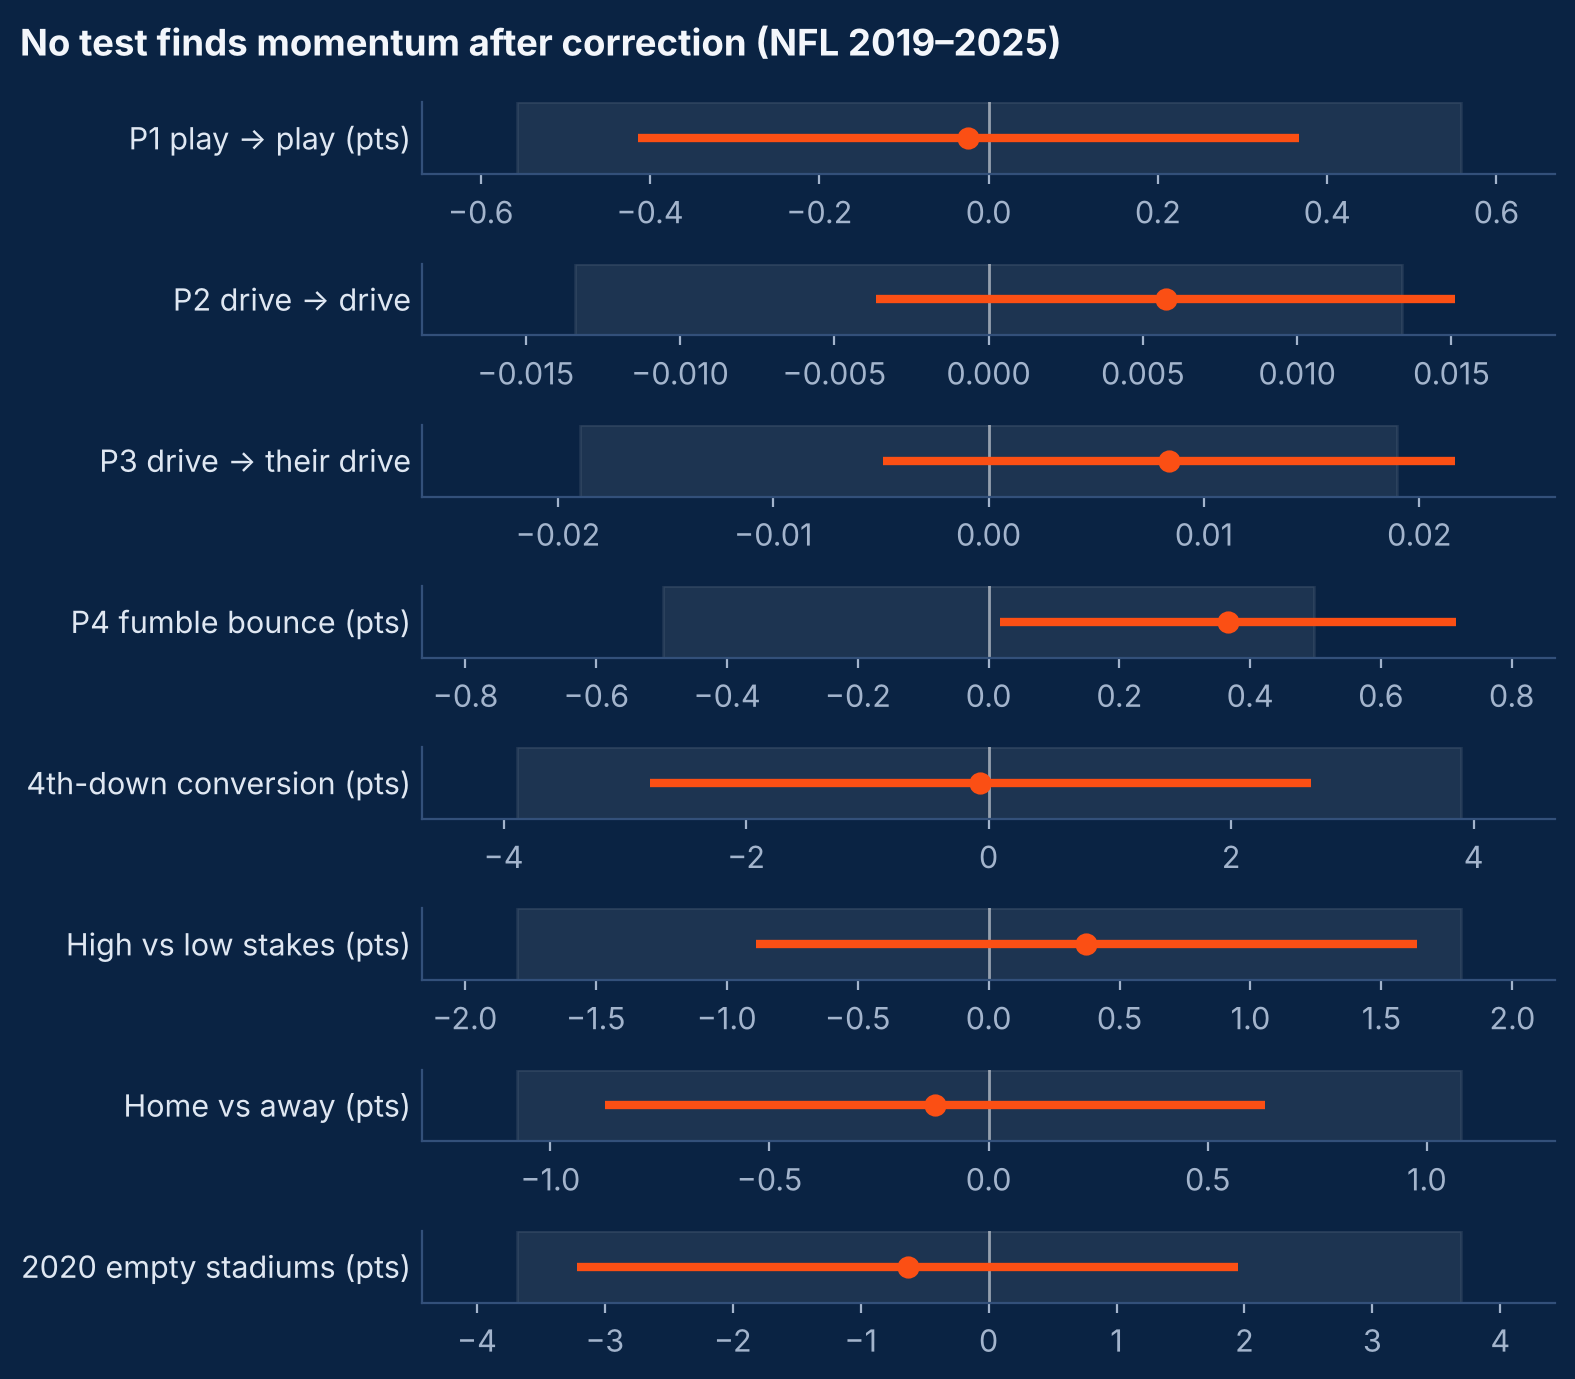

In [6]:
H = R["holdout_nfl"]
items = [("P1 play → play (pts)", H["P1"]["excess"]*100, H["P1"]["null_sd"]*100), ("P2 drive → drive", H["P2"]["excess"], H["P2"]["null_sd"]),
         ("P3 drive → their drive", H["P3"]["excess"], H["P3"]["null_sd"]), ("P4 fumble bounce (pts)", H["P4"]["est"], H["P4"]["se"]),
         ("4th-down conversion (pts)", H["big_moments"]["excess"]*100, H["big_moments"]["null_sd"]*100),
         ("High vs low stakes (pts)", H["stakes_crowd"]["stakes_gap"]["excess"]*100, H["stakes_crowd"]["stakes_gap"]["null_sd"]*100),
         ("Home vs away (pts)", H["stakes_crowd"]["home_minus_away"]["excess"]*100, H["stakes_crowd"]["home_minus_away"]["null_sd"]*100),
         ("2020 empty stadiums (pts)", -H["crowd_2020"]["did"]["excess"]*100, H["crowd_2020"]["did"]["null_sd"]*100)]
fig, axes = plt.subplots(len(items), 1, figsize=(8, 7))
for ax, (lab, e, sd) in zip(axes, items):
    R_ = max(abs(e) + 2*sd, 2.8*sd) * 1.2
    ax.axvspan(-2.8*sd, 2.8*sd, color="#ffffff14"); ax.axvline(0, color="#ffffff88", lw=1)
    ax.errorbar(e, 0, xerr=1.96*sd, fmt="o", color=OR, lw=3, ms=7); ax.set_xlim(-R_, R_); ax.set_yticks([]); ax.set_ylabel(lab, rotation=0, ha="right", va="center")
fig.suptitle("No test finds momentum after correction (NFL 2019–2025)", x=.02, ha="left", fontweight="bold"); fig.tight_layout(); fig.savefig(FIG / "every_test.png", dpi=200); plt.show()

## 5. Who plays with momentum? Team-seasons on a funnel

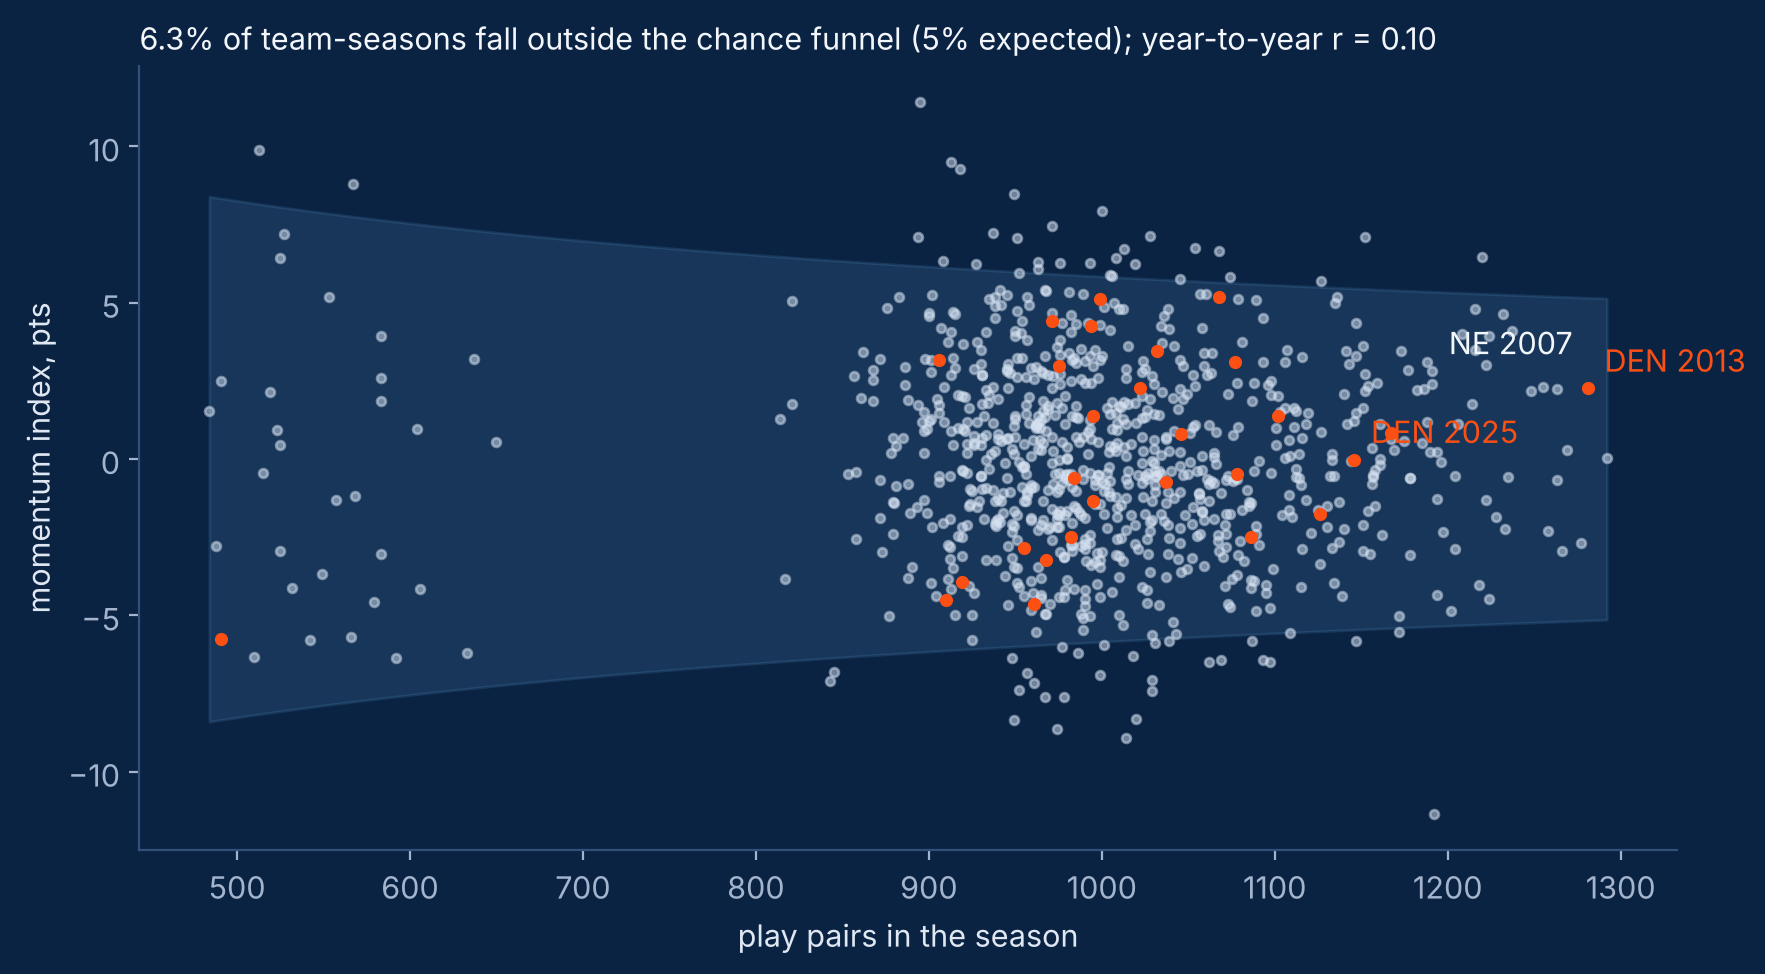

In [7]:
ts = pd.DataFrame(E["team_seasons"]); k = np.median(ts.null_sd * np.sqrt(ts.n_pairs)); xs = np.linspace(ts.n_pairs.min(), ts.n_pairs.max(), 100)
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(xs, -1.96*k/np.sqrt(xs)*100, 1.96*k/np.sqrt(xs)*100, color=ICE, alpha=.12)
ax.scatter(ts.n_pairs, ts.excess*100, s=10, color="#d6e2f2", alpha=.5)
den = ts[ts.posteam == "DEN"]; ax.scatter(den.n_pairs, den.excess*100, s=14, color=OR)
for t, y in [("DEN", 2025), ("NE", 2007), ("DEN", 2013)]:
    r = ts[(ts.posteam == t) & (ts.season == y)].iloc[0]; ax.annotate(f"{t} {y}", (r.n_pairs, r.excess*100), xytext=(6, 6), textcoords="offset points", color=OR if t == "DEN" else "#f3f6fb")
rel = E["team_reliability"]
ax.set_title(f"{rel['share_outside_95']:.1%} of team-seasons fall outside the chance funnel (5% expected); year-to-year r = {rel['yoy_corr_momentum']:.2f}", loc="left", fontsize=11)
ax.set_xlabel("play pairs in the season"); ax.set_ylabel("momentum index, pts"); fig.tight_layout(); fig.savefig(FIG / "team_funnel.png", dpi=200); plt.show()

In [8]:
q = pd.DataFrame(E["qbs"]); q.assign(excess=q.excess*100).sort_values("z")[["passer_player_name", "games", "excess", "z"]].iloc[np.r_[0:5, -5:0]].round(2)

,passer_player_name,games,excess,z
50,M.Ryan,241,-2.35,-3.04
93,B.Purdy,62,-4.56,-2.84
86,J.Herbert,106,-3.17,-2.66
61,N.Foles,63,-3.05,-2.13
49,J.Flacco,217,-1.80,-2.11
38,E.Manning,245,1.36,1.81
65,G.Smith,105,2.23,1.92
59,R.Tannehill,156,1.92,1.98
44,T.Romo,132,2.39,2.17
46,D.Anderson,51,5.66,3.02


## 6. The Broncos' 17–1 in one-score games

Record [17, 1], expected wins 10.0, P(>=17) = 0.00030 (1 in 3,333)
Best 18-game close-game stretches:
team  best18        end      start
  NE      17 2004-12-12 2002-11-24
  KC      17 2025-01-26 2023-12-25
 DEN      17 2026-11-08 2025-10-05
 CAR      16 2015-12-20 2013-11-10
 IND      16 2009-12-17 2008-09-14
Close-game luck, year-to-year correlation: -0.003


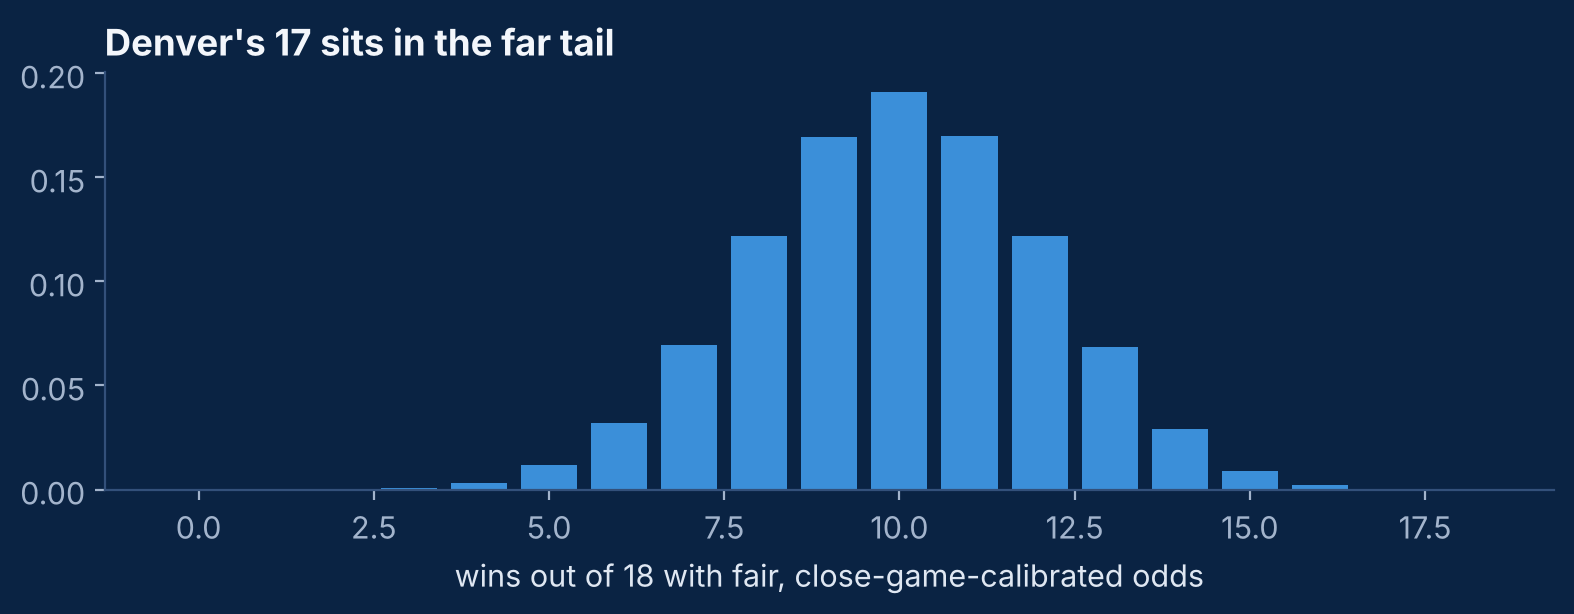

In [9]:
B = E["broncos"]; h = np.array(B["sim_hist"]); p = h[B["den_record"][0]:].sum() / h.sum()
print(f"Record {B['den_record']}, expected wins {B['den_expected_wins']:.1f}, P(>=17) = {p:.5f} (1 in {1/p:,.0f})")
print("Best 18-game close-game stretches:"); print(pd.DataFrame(B["league_best18"]).head(5).to_string(index=False))
print("Close-game luck, year-to-year correlation:", round(E["close_persistence"]["yoy_corr"], 3))
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.bar(range(len(h)), h/h.sum(), color=[OR if i >= 17 else "#3b8fd9" for i in range(len(h))])
ax.set_xlabel("wins out of 18 with fair, close-game-calibrated odds"); ax.set_title("Denver's 17 sits in the far tail", loc="left", fontweight="bold"); fig.tight_layout(); fig.savefig(FIG / "broncos_close_games.png", dpi=200); plt.show()

## 7. Run a test live

The 2025 season alone, 300 shuffles, so you can see the machinery work end to end.

In [10]:
from analysis import prep_plays, p1_play_carryover
p = pd.read_parquet(ROOT / "data" / "clean" / "nfl_plays_model.parquet")
res = p1_play_carryover(prep_plays(p, [2025]), n_perm=300)
{k: round(float(v) * (100 if k in ("obs", "null_mean", "excess", "null_sd", "mde80") else 1), 3) for k, v in res.items() if k != "null"}

{'obs': 0.346,
 'null_mean': 0.549,
 'null_sd': 0.509,
 'excess': -0.203,
 'z': -0.4,
 'p': 0.684,
 'n_pairs': 33133.0,
 'mde80': 1.425}

## Limits

- A positive play-to-play result could come from slow drift inside a half (an injury, an adjustment); the simulation shows that. The real result is zero, so drift is not masking anything, but it is why P3 and P4 exist.
- College data has no flags for aborted snaps or out-of-bounds fumbles, so college fumble recovery fails the balance check and college P4 is not a natural experiment. College play order had to be rebuilt from ESPN sequence numbers.
- College's slight negative play-to-play result may come from spot-recording error, which pushes two neighbouring plays in opposite directions. A spot-free outcome (completion on consecutive passes) is the natural next check.
- Momentum is a feeling and a decision-making force; coaches clearly change play calls after big moments (as the video showed). This tests whether outcomes follow.

Sources are listed in the README.